# Pixl: generate scenes

Loads a model trained by `python -m pixl.train` (on this machine or in the Docker image) and draws scenes from captions. Run with the kernel's working directory set to `notebooks/`. Set `CHECKPOINT` to the run's checkpoint, `GUIDANCES` to the guidance values to compare, and edit `PROMPTS` (written with `caption()`) to try your own captions; a default quick run lives at `../checkpoints/scenes-four-quick/checkpoint.pt`. No dataset is downloaded: the checkpoint holds the weights and preview scenes, while the installed `pixl` package supplies the palette and tokenizer. Use the same palette and tokenizer as training. `train.ipynb` shows a run's training curves.

In [10]:
import os
import textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib import pyplot as plt

from pixl.model import encode_captions
from pixl.preprocess import decode, load_palette
from pixl.tokenizer import Tokenizer
from pixl.train import load_model, pick_device

PALETTE = load_palette()


def show(rows: list[tuple[str, np.ndarray]], captions: list[str], title: str) -> None:
    """Draws rows of 32x32 token images, one column per caption.

    Args:
        rows: (row label, (n, 32, 32) tokens) pairs; transparent pixels show the axes background.
        captions: Caption of each column, written above the first row.
        title: Figure title.
    """
    figure, axes = plt.subplots(len(rows), len(captions), figsize=(2 * len(captions), 2 * len(rows) + 1.5), squeeze=False)
    for axis_row, (label, images) in zip(axes, rows):
        axis_row[0].set_ylabel(label)
        for axis, image in zip(axis_row, images):
            axis.imshow(decode(image, PALETTE), interpolation="nearest")
            axis.set_xticks([])
            axis.set_yticks([])
    for axis, text in zip(axes[0], captions):
        axis.set_title(textwrap.fill(text, 28), fontsize=7)
    figure.suptitle(title)
    figure.tight_layout()
    plt.show()


def caption(objects: dict[str, str], ground: str = "") -> str:
    """A caption in the training format.

    Args:
        objects: Quadrant ("top left", "top right", "bottom left", "bottom right") to an
            object label with its article ("a red potion"), listed in this order;
            training lists the quadrants in random order.
        ground: The ground ("grass"), or "" for sprite packs drawn without one.
    """
    parts = [f"{thing} at the {place}" for place, thing in objects.items()]
    text = f"{', '.join(parts[:-1])} and {parts[-1]}"
    return f"{text} on {ground}" if ground else text

## Settings

In [11]:
CHECKPOINT = Path("../checkpoints/scenes-four-margin/checkpoint.pt")  # relative to notebooks/
DEVICE = "cpu"  # "auto": CUDA, then Apple's GPU, then the CPU; sampling on the Mac's GPU can freeze the terminal
CPU_THREADS = 4
TEMPERATURE = 0.7  # below 1 picks likely colours more often
GUIDANCE = 3.0  # classifier-free guidance; 1 uses the caption as is
SEED = 0
GUIDANCES = [1.0, 2.0, 3.0, 5.0]  # one row per value in the caption tests
PROMPTS = [  # four labels from one sprite pack each, on one of that pack's grounds, as in training
    caption({"top left": "a green pine tree", "top right": "a small wooden hut", "bottom left": "a wooden barrel", "bottom right": "a beehive"}, "grass"),
    caption({"top left": "a knight with gray helmet", "top right": "an orange cyclops", "bottom left": "an anvil", "bottom right": "a gravestone"}, "a sandy floor"),
    caption({"top left": "a cow", "top right": "a sheep", "bottom left": "a hay bale", "bottom right": "a farmer"}, "tilled soil"),
    caption({"top left": "a green heavy tank", "top right": "a blue helicopter", "bottom left": "a red army base", "bottom right": "a gray supply truck"}, "a road"),
    caption({"top left": "a green tank", "top right": "a red armored truck", "bottom left": "a health pack", "bottom right": "a yellow bomb"}, "grass"),
    caption({"top left": "a yellow motorcycle", "top right": "a woman walking", "bottom left": "a red scooter", "bottom right": "a man pointing"}),
    # These two each hold a pair never seen together in training: red house and sword; long sword and helmet.
    caption({"top left": "a red house", "top right": "a skeleton", "bottom left": "a sword", "bottom right": "a gold coin"}, "tall grass"),
    caption({"top left": "a hydra", "top right": "a long sword", "bottom left": "a helmet", "bottom right": "a gold pile"}, "ice"),
]
SCENE = {"top left": "a purple robed wizard", "top right": "a closed treasure chest",  # clockwise from the top left
         "bottom right": "a red potion", "bottom left": "a brown bat"}
GROUND = "a dark dungeon floor"
# SCENE's objects turned clockwise one quadrant per caption: they should follow their captions.
THINGS = list(SCENE.values())
TURNED = [caption(dict(zip(SCENE, THINGS[-turn:] + THINGS[:-turn])), GROUND) for turn in range(4)]
# SCENE's layout listed in four orders: the scenes should keep the same layout.
ORDERS = [("top left", "top right", "bottom left", "bottom right"), ("bottom right", "bottom left", "top right", "top left"),
          ("top right", "bottom left", "bottom right", "top left"), ("bottom left", "top left", "bottom right", "top right")]
REORDERED = [caption({place: SCENE[place] for place in order}, GROUND) for order in ORDERS]
DEVICE = pick_device(DEVICE)
if DEVICE == "cpu":
    # A few threads, and this kernel at the lowest priority until it restarts, so the Mac stays responsive.
    torch.set_num_threads(CPU_THREADS)
    os.nice(max(0, 19 - os.nice(0)))

## Model

The run's settings, how far it trained, and its final scores after the last step. Full runs score every evaluation scene; quick runs score every 50th scene. **position** is how often a scene's caption beats the same caption with two objects' quadrants exchanged (chance 0.5).

In [12]:
model, state = load_model(CHECKPOINT, DEVICE)
tokenizer = Tokenizer.load()
print(f"{CHECKPOINT}: step {state['step']:,} | {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")
print("settings:", state["settings"])
print("inputs:", state["fingerprints"])
if "final" in state:
    kinds = ("train", "new sprites", "new pair")
    display(pd.DataFrame({kind: {m: state["final"][f"{kind} {m}"] for m in ("loss", "position")} for kind in kinds}).round(3))


@torch.no_grad()
def draw(texts: list[str], seed: int = SEED, guidance: float = GUIDANCE) -> np.ndarray:
    """(len(texts), 32, 32) samples for the captions, from a fixed seed."""
    torch.manual_seed(seed)
    ids = encode_captions(texts, tokenizer, length=model.config.caption).to(DEVICE)
    images = model.generate(ids, temperature=TEMPERATURE, top_k=32, guidance=guidance)
    return images.view(-1, 32, 32).cpu().numpy()


def sweep(texts: list[str], title: str) -> None:
    """Draws every caption once per guidance value in GUIDANCES, all from the same seed."""
    show([(f"guidance {guidance:g}", draw(texts, guidance=guidance)) for guidance in GUIDANCES], texts, title)

../checkpoints/scenes-four-margin/checkpoint.pt: step 31,250 | 26.7M parameters
settings: {'run': 'scenes-four-margin', 'batch': 32, 'epochs': 1, 'peak_lr': 0.0003, 'min_lr': 3e-05, 'warmup': 1000, 'eval_every': 2000, 'quick': False, 'margin': 2.0}
inputs: {'data': '2c42c6b6389e42db', 'tokenizer': '965d23f1052f4953', 'palette': '88c283153cf63ad3'}


,train,new sprites,new pair
loss,0.016,1.576,0.016
position,0.822,0.598,0.802


## Preview scenes

The scenes training previewed (4 train scenes, then 4 with an object pair never seen together), two samples of each caption, and samples of the same captions with two objects' quadrants exchanged: if the model reads positions, those two objects trade places.

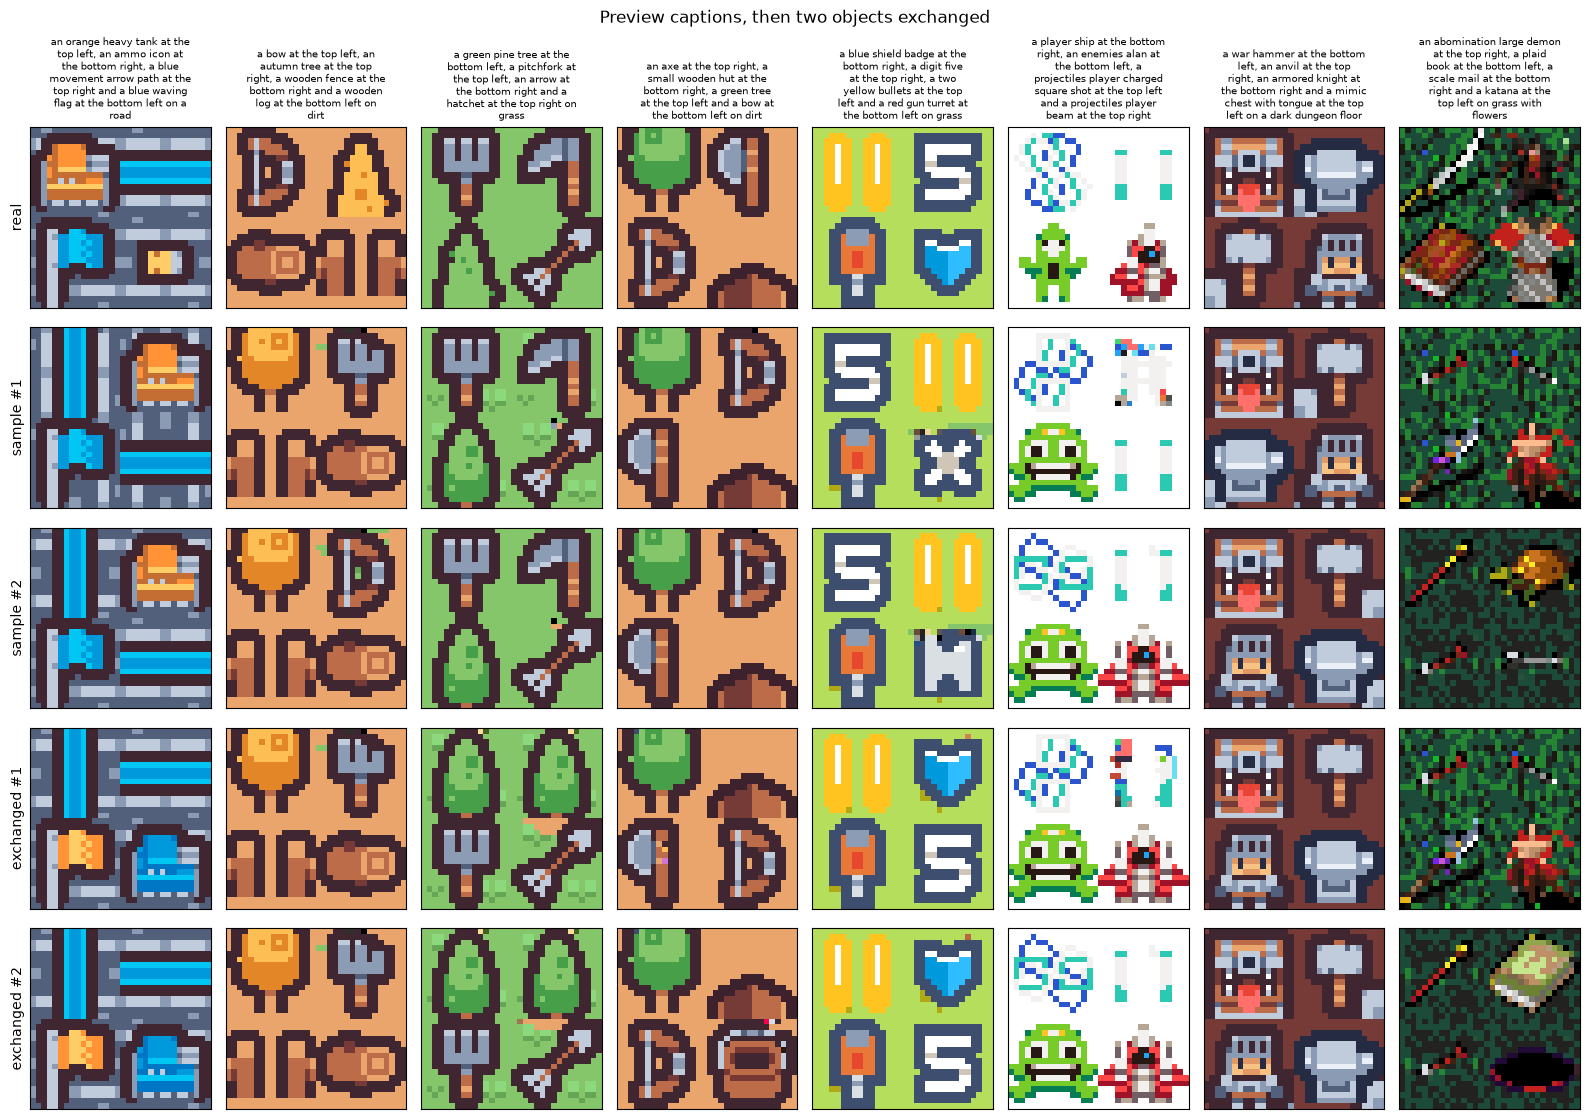

In [13]:
preview = state["preview"]
show([("real", preview["tokens"].numpy()), ("sample #1", draw(preview["captions"])), ("sample #2", draw(preview["captions"], SEED + 1)),
      ("exchanged #1", draw(preview["swapped"])), ("exchanged #2", draw(preview["swapped"], SEED + 1))],
     preview["captions"], "Preview captions, then two objects exchanged")

## Your captions across guidance

`PROMPTS`, one row per value in `GUIDANCES`, all from the same seed. Guidance 1 uses the caption as is; higher values push each pixel further towards what the caption predicts and away from what an empty caption predicts. Each caption names four objects from one sprite pack, their quadrants and, for most packs, the ground.

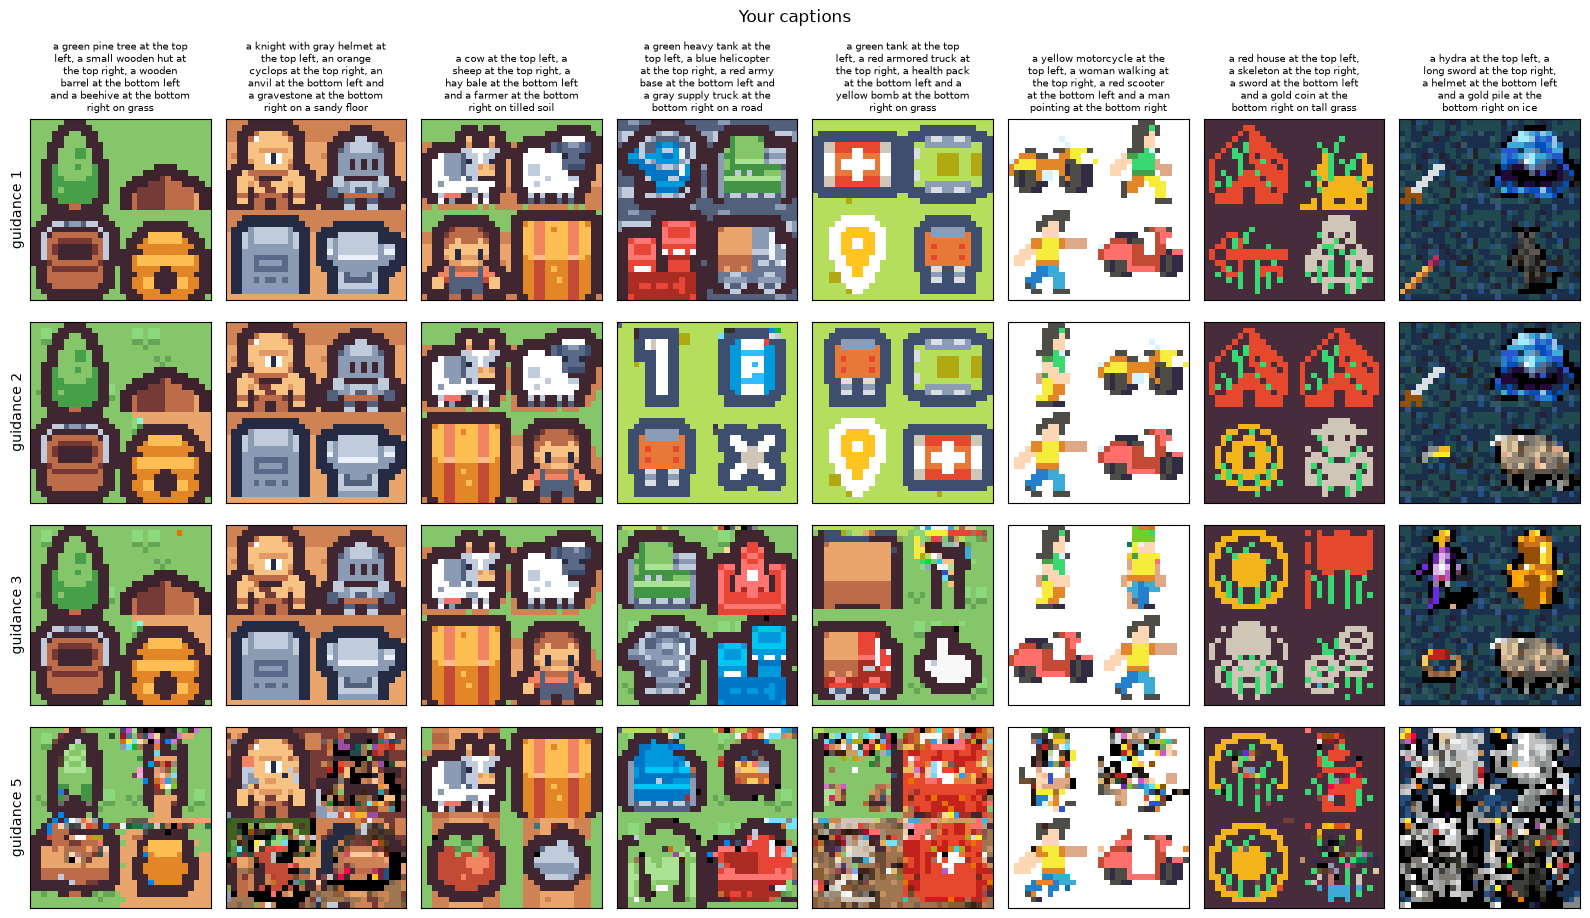

In [14]:
sweep(PROMPTS, "Your captions")

## Do objects follow their quadrants?

The same four objects, turned clockwise one quadrant per column. If the model reads positions, each object moves with its caption.

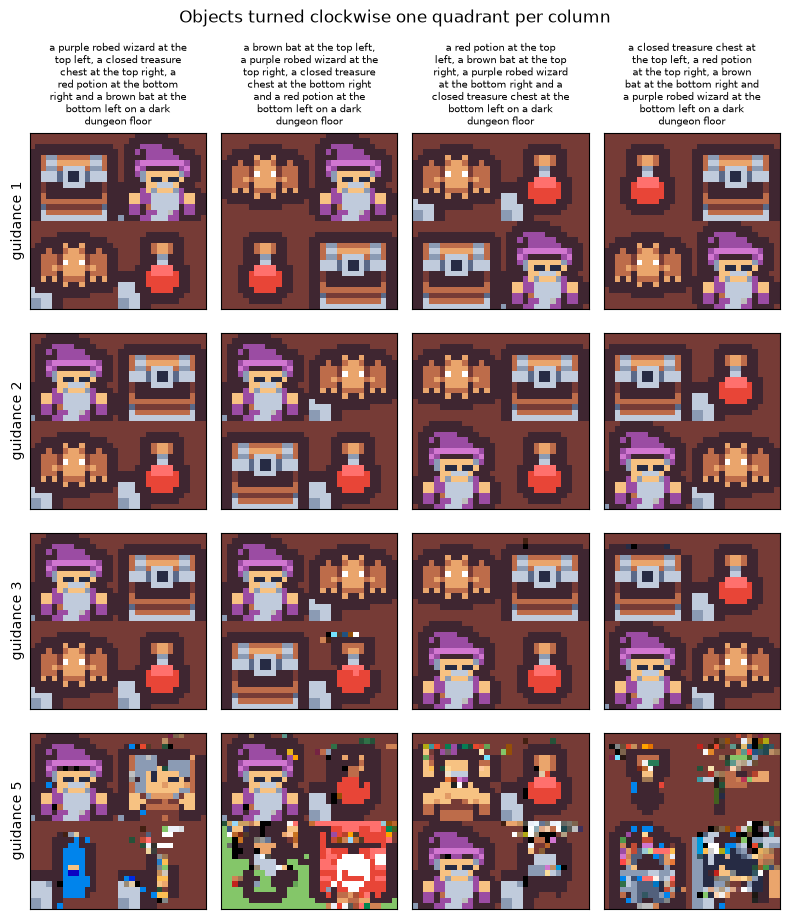

In [15]:
sweep(TURNED, "Objects turned clockwise one quadrant per column")

## Does the listing order matter?

The first column's layout, with the quadrants listed in four different orders. Training lists them in random order, so all four columns should show the same layout.

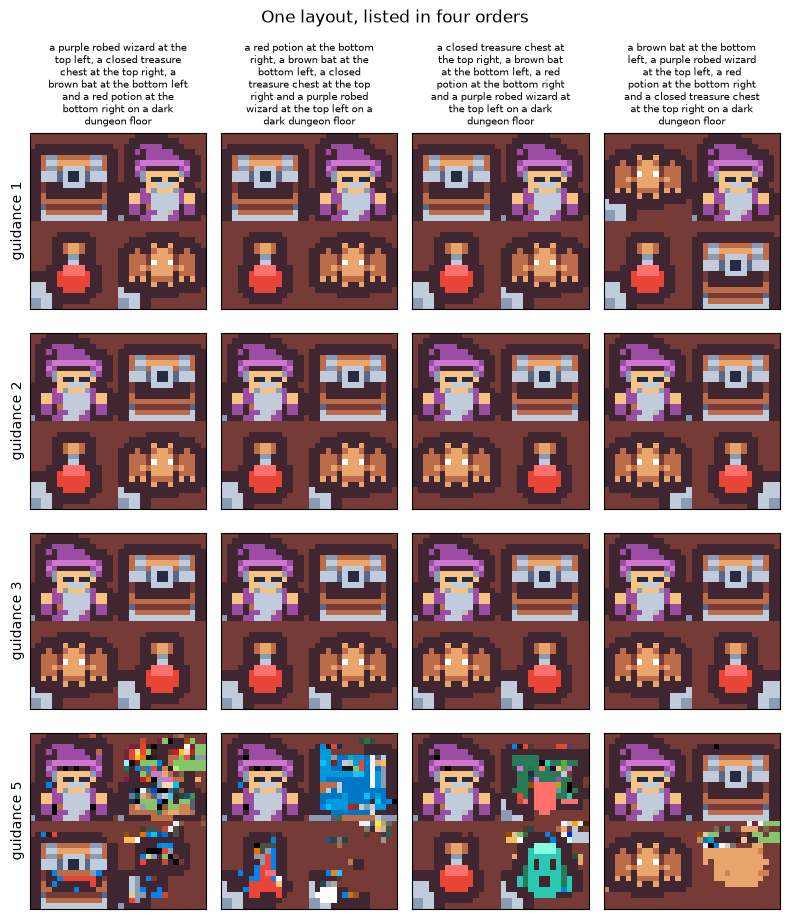

In [16]:
sweep(REORDERED, "One layout, listed in four orders")